In [2]:
a = 1
print(a)

1


In [3]:
!ls

sample_data


In [4]:
!apt-get install -y -qq software-properties-common python-software-properties module-init-tools

E: Package 'python-software-properties' has no installation candidate
E: Package 'module-init-tools' has no installation candidate


In [5]:
!add-apt-repository -y ppa:alessandro-strada/ppa 2>&1 > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [6]:
!apt-get update -qq 2>&1 > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [7]:
!apt-get -y install -qq google-drive-ocamlfuse fuse

Selecting previously unselected package libfuse3-3:amd64.
(Reading database ... 122816 files and directories currently installed.)
Preparing to unpack .../libfuse3-3_3.14.0-5build1_amd64.deb ...
Unpacking libfuse3-3:amd64 (3.14.0-5build1) ...
Selecting previously unselected package google-drive-ocamlfuse.
Preparing to unpack .../google-drive-ocamlfuse_0.9.0-0ubuntu1~bpo24.04.1_amd64.deb ...
Unpacking google-drive-ocamlfuse (0.9.0-0ubuntu1~bpo24.04.1) ...
Setting up libfuse3-3:amd64 (3.14.0-5build1) ...
Setting up google-drive-ocamlfuse (0.9.0-0ubuntu1~bpo24.04.1) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/li

In [8]:
from google.colab import auth

In [9]:
auth.authenticate_user()

In [10]:
from oauth2client.client import GoogleCredentials

In [11]:
creds = GoogleCredentials.get_application_default()

In [12]:
import getpass

In [13]:
!google-drive-ocamlfuse -headless -id={creds.client_id} -secret={creds.client_secret} < /dev/null 2>&1 | grep URL

Please, open the following URL in a web browser: https://accounts.google.com/o/oauth2/auth?client_id=None&redirect_uri=http%3A%2F%2F127.0.0.1%3A8080%2Foauth2callback&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fdrive&response_type=code&access_type=offline&approval_prompt=force


In [14]:
vcode = getpass.getpass()

··········


In [15]:
!echo {vcode} | google-drive-ocamlfuse -headless -id={creds.client_id} -secret={creds.client_secret}

Please, open the following URL in a web browser: https://accounts.google.com/o/oauth2/auth?client_id=None&redirect_uri=http%3A%2F%2F127.0.0.1%3A8080%2Foauth2callback&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fdrive&response_type=code&access_type=offline&approval_prompt=force
Please enter the verification code: Cannot retrieve auth tokens.
Failure("OAuth2 for devices error: invalid_client (HTTP response code: 401)")


In [16]:
from google.colab import drive

# 掛載 Google Drive 到 /content/drive 目錄
drive.mount('/content/drive')

# 掛載成功後，您可以使用 !ls '/content/drive/MyDrive' 來查看雲端硬碟的檔案

Mounted at /content/drive


In [17]:
!mkdir -p drive
!google-drive-ocamlfuse drive

Thread 1 killed on uncaught exception Unix.Unix_error(50, "bind", "")
/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening 'https://accounts.google.com/o/oauth2/auth?client_id=None&redirect_uri=http%3A%2F%2F127.0.0.1%3A8080%2Foauth2callback&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fdrive&response_type=code&access_type=offline&approval_prompt=force'
/bin/sh: 1: firefox: not found
/bin/sh: 1: google-chrome: not found
/bin/sh: 1: chromium-browser: not found
/usr/bin/open: 882: www-browser: not found
/usr/bin/open: 882: links2: not found
/usr/bin/open: 882: elinks: not found
/usr/bin/open: 882: links: not found
/usr/bin/open: 882: lynx: not found
/usr/bin/open: 882: w3m: not found
xdg-open: no method available for opening 'https://accounts.google.c

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
# Load the Drive helper and mount
from google.colab import drive
#This will prompt for authorization.
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
!ls

drive  sample_data


In [21]:
import os
os.chdir("drive")

In [22]:
os.chdir('../')

In [23]:
!python XXX.py

python3: can't open file '/content/XXX.py': [Errno 2] No such file or directory


In [25]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 載入 MNIST 手寫數字資料集
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("訓練圖片數量：", len(x_train))
print("測試圖片數量：", len(x_test))
print("圖片尺寸：", x_train.shape[1:])
print("前10筆標籤：", y_train[:10])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
訓練圖片數量： 60000
測試圖片數量： 10000
圖片尺寸： (28, 28)
前10筆標籤： [5 0 4 1 9 2 1 3 1 4]


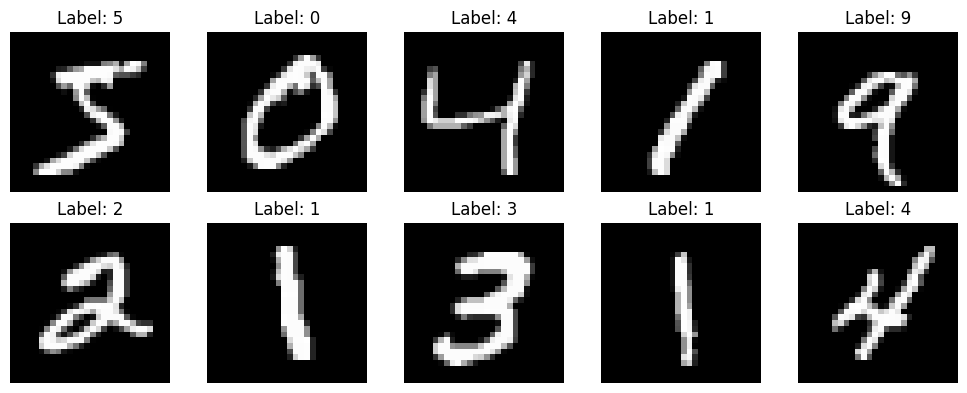

In [26]:
# 將像素值從 0～255 正規化到 0～1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 顯示前10張手寫數字圖片
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
# 建立卷積神經網路 CNN
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(
        32, kernel_size=3, activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# 設定模型訓練方式
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 顯示模型架構
model.summary()

# 開始訓練
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 27s 62ms/step - accuracy: 0.9180 - loss: 0.2865 - val_accuracy: 0.9758 - val_loss: 0.0949
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 55ms/step - accuracy: 0.9751 - loss: 0.0867 - val_accuracy: 0.9813 - val_loss: 0.0692
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 61ms/step - accuracy: 0.9832 - loss: 0.0575 - val_accuracy: 0.9860 - val_loss: 0.0564
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 55ms/step - accuracy: 0.9869 - loss: 0.0437 - val_accuracy: 0.9858 - val_loss: 0.0525
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 57ms/step - accuracy: 0.9895 - loss: 0.0349 - val_accuracy: 0.9870 - val_loss: 0.0496


測試損失值：0.0450
測試準確率：98.57%


/tmp/ipykernel_3144/4233557764.py:42: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3144/4233557764.py:42: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3144/4233557764.py:42: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3144/4233557764.py:42: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3144/4233557764.py:42: UserWarning: Glyph 30906 (\N{CJK UNIFIED IDEOGRAPH-78BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/co

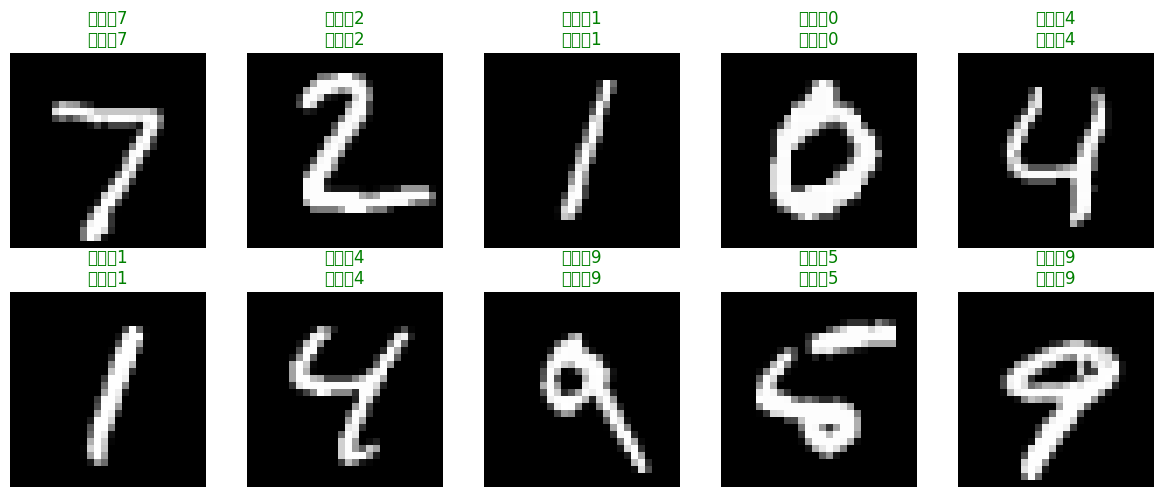

In [28]:
import os
# 安裝中文字型
!apt-get install -y -qq fonts-wqy-microhei

# 設定 matplotlib 支援中文
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['WenQuanYi Micro Hei'] # 設定中文字型
plt.rcParams['axes.unicode_minus'] = False # 正常顯示負號

# 評估模型
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print(f"測試損失值：{test_loss:.4f}")
print(f"測試準確率：{test_accuracy * 100:.2f}%")

# 預測前10張測試圖片
predictions = model.predict(x_test[:10], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")

    color = (
        "green" if predicted_labels[i] == y_test[i]
        else "red"
    )

    plt.title(
        f"預測：{predicted_labels[i]}\n"
        f"正確：{y_test[i]}",
        color=color
    )
    plt.axis(
        "off"
    )

plt.tight_layout()
plt.show()